# Airline Selection Analysis

I hovednotebooken (`flight_delay_prediction.ipynb`) træner vi på alle flyselskaber samlet. Her undersøger vi, om det giver mening at fokusere på **ét enkelt selskab**, og i så fald hvilket.

Notebooken bygger på `cleaned_flights.csv`, som allerede er renset i hovednotebooken (aflyste/omdirigerede flyvninger og manglende `ArrDelay` er fjernet, og `Delayed = (ArrDelay > 15)`).

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CLEANED_PATH = Path("cleaned_flights.csv")
RAW_PATH = Path("raw_flights.csv")

if CLEANED_PATH.exists():
    df = pd.read_csv(CLEANED_PATH)
else:
    # Samme cleaning som i hovednotebooken
    raw = pd.read_csv(
        RAW_PATH,
        usecols=["FlightDate", "Month", "DayOfWeek", "Reporting_Airline", "Origin", "Dest",
                 "CRSDepTime", "Distance", "ArrDelay", "Cancelled", "Diverted"],
    )
    raw = raw[(raw["Cancelled"] == 0) & (raw["Diverted"] == 0)]
    raw = raw.dropna(subset=["ArrDelay"])
    raw["Delayed"] = (raw["ArrDelay"] > 15).astype(int)
    df = raw.drop(columns=["ArrDelay", "Cancelled", "Diverted"])

print(f"{len(df):,} flyvninger, {df['Reporting_Airline'].nunique()} selskaber")
print(f"Samlet delay rate: {df['Delayed'].mean():.1%}")
df.head()

6,879,484 flyvninger, 14 selskaber
Samlet delay rate: 21.6%


,FlightDate,Month,DayOfWeek,Reporting_Airline,Origin,Dest,CRSDepTime,Distance,Delayed
0,2025-01-01,1,3,AA,JFK,LAX,659,2475.0,0
1,2025-01-02,1,4,AA,JFK,LAX,659,2475.0,0
2,2025-01-03,1,5,AA,JFK,LAX,659,2475.0,0
3,2025-01-04,1,6,AA,JFK,LAX,700,2475.0,0
4,2025-01-05,1,7,AA,JFK,LAX,659,2475.0,0


## Step 1: Airline Overview

Vi beregner seks nøgletal pr. selskab for at vurdere, hvilket der egner sig bedst som modelleringsgrundlag:

| Nøgletal | Hvad vi leder efter |
|---|---|
| **Antal flyvninger** | Nok data til at træne og teste robust (mindst ~300k) |
| **Delay rate** | Ikke for lav – ellers bliver det trivielt at gætte "on time", og modellen lærer kun majoritetsklassen |
| **Unikke ruter** | Mange Origin–Dest-par giver variation i features som rute, distance og lufthavn |
| **Unikke Origin-airports** | Netværkets bredde – hvor mange forskellige lufthavnsforhold modellen ser |
| **Sæsonvariation** (std. af månedlig delay rate) | Et tydeligt sæsonmønster betyder, at tidsfeatures (måned, ugedag) har noget at lære af |
| **Hub-koncentration** (andel fra top-5 lufthavne) | Høj = hub-and-spoke (få store knudepunkter), lav = point-to-point. Giver os en operationel historie |

In [ ]:
df["Route"] = df["Origin"] + "-" + df["Dest"]
grouped = df.groupby("Reporting_Airline")


def hub_concentration(origins: pd.Series, top_n: int = 5) -> float:
    """Andel af flyvninger fra selskabets top_n travleste afgangslufthavne."""
    return origins.value_counts().head(top_n).sum() / len(origins)


monthly_rate = df.groupby(["Reporting_Airline", "Month"])["Delayed"].mean()

overview = pd.DataFrame({
    "Flights": grouped.size(),
    "DelayRate": grouped["Delayed"].mean(),
    "UniqueRoutes": grouped["Route"].nunique(),
    "UniqueOrigins": grouped["Origin"].nunique(),
    "SeasonalStd": monthly_rate.groupby(level="Reporting_Airline").std(),
    "HubConcentration": grouped["Origin"].agg(hub_concentration),
    "TopHubs": grouped["Origin"].agg(lambda s: ", ".join(s.value_counts().head(5).index)),
}).sort_values("Flights", ascending=False)

overview.style.format({
    "Flights": "{:,}",
    "DelayRate": "{:.1%}",
    "SeasonalStd": "{:.3f}",
    "HubConcentration": "{:.1%}",
})

,Flights,DelayRate,UniqueRoutes,UniqueOrigins,SeasonalStd,HubConcentration,TopHubs
Reporting_Airline,,,,,,,
WN,"1,376,837",20.6%,1929,104,0.044,27.8%,"DEN, LAS, BWI, DAL, PHX"
DL,"1,012,427",19.2%,1167,153,0.041,44.3%,"ATL, MSP, DTW, SLC, LAX"
AA,"952,841",25.0%,1194,133,0.049,46.9%,"DFW, CLT, MIA, ORD, PHX"
OO,"825,202",20.1%,1767,265,0.036,29.9%,"DEN, ORD, LAX, SLC, SFO"
UA,"786,377",20.8%,1028,127,0.041,50.1%,"DEN, ORD, IAH, EWR, SFO"
YX,"334,043",20.9%,962,98,0.052,46.5%,"LGA, BOS, ORD, DCA, EWR"
MQ,"291,835",20.4%,902,177,0.033,47.9%,"DFW, ORD, MIA, PHX, CLT"
AS,"241,927",22.2%,437,89,0.051,53.6%,"SEA, PDX, ANC, SAN, SFO"
OH,"236,682",26.8%,596,113,0.065,51.5%,"CLT, DCA, DFW, PHL, DAY"


## Step 2: Visualiseringer

### 2.1 Størrelse vs. delay rate
Kandidaterne skal ligge til højre for 300k-linjen (nok data) og helst over gennemsnittet på y-aksen (mere signal i minoritetsklassen).

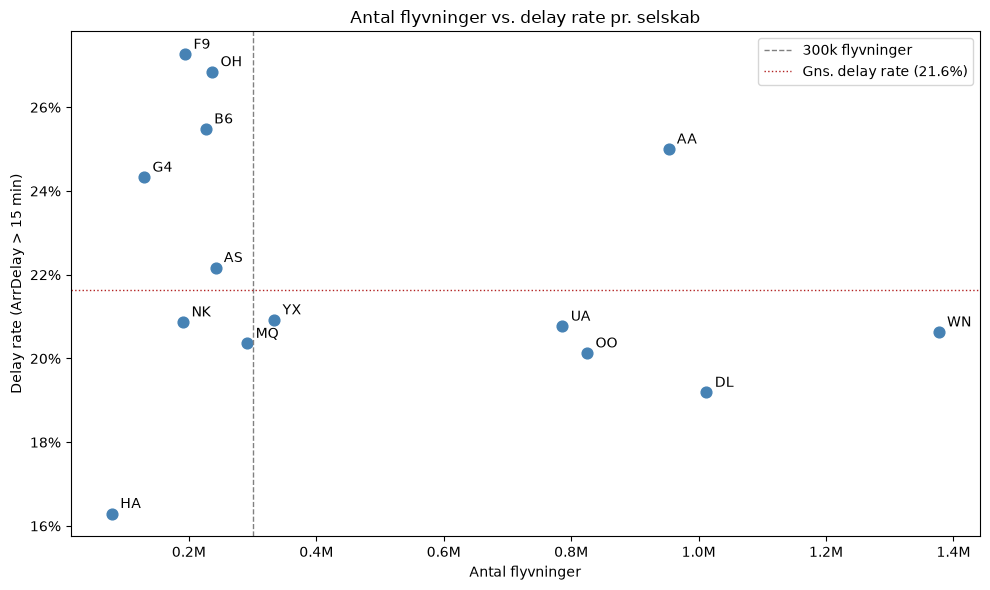

In [ ]:
MIN_FLIGHTS = 300_000
overall_rate = df["Delayed"].mean()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(overview["Flights"], overview["DelayRate"], s=60, color="steelblue")
for airline, row in overview.iterrows():
    ax.annotate(airline, (row["Flights"], row["DelayRate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=10)

ax.axvline(MIN_FLIGHTS, color="grey", linestyle="--", linewidth=1, label="300k flyvninger")
ax.axhline(overall_rate, color="firebrick", linestyle=":", linewidth=1,
           label=f"Gns. delay rate ({overall_rate:.1%})")
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1e6:.1f}M")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Antal flyvninger")
ax.set_ylabel("Delay rate (ArrDelay > 15 min)")
ax.set_title("Antal flyvninger vs. delay rate pr. selskab")
ax.legend()
plt.tight_layout()
plt.show()

### 2.2 Hub-koncentration
Høj andel = hub-and-spoke-netværk, hvor forsinkelser i få knudepunkter spreder sig. Lav andel = point-to-point.

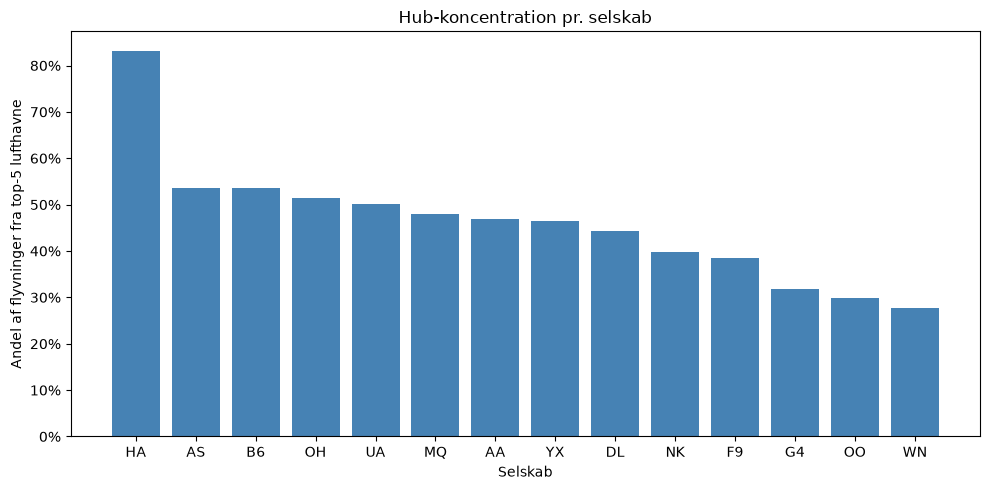

In [4]:
hub_sorted = overview["HubConcentration"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(hub_sorted.index, hub_sorted.values, color="steelblue")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Selskab")
ax.set_ylabel("Andel af flyvninger fra top-5 lufthavne")
ax.set_title("Hub-koncentration pr. selskab")
plt.tight_layout()
plt.show()

### 2.3 Sæsonmønster for de 5 største selskaber

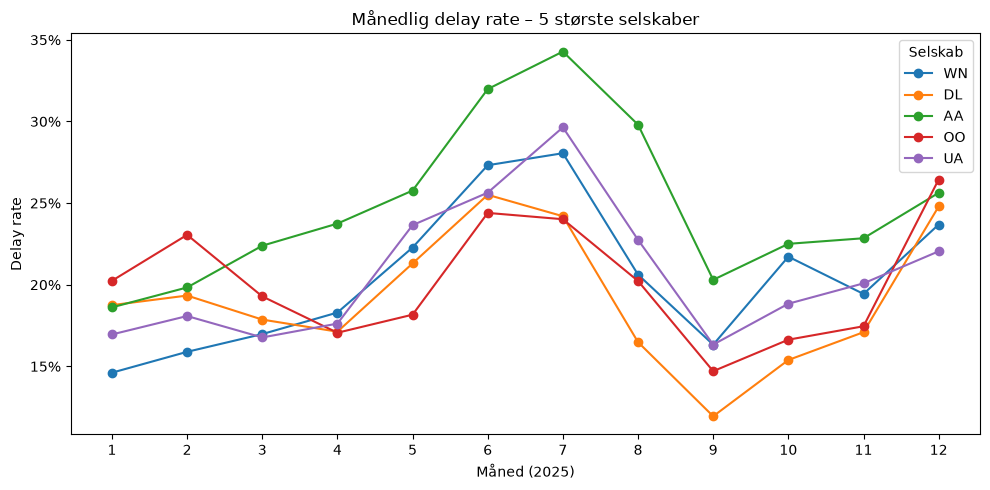

In [5]:
top5_airlines = overview.head(5).index

monthly_top5 = (
    df[df["Reporting_Airline"].isin(top5_airlines)]
    .groupby(["Month", "Reporting_Airline"])["Delayed"].mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(10, 5))
for airline in top5_airlines:
    ax.plot(monthly_top5.index, monthly_top5[airline], marker="o", label=airline)

ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Måned (2025)")
ax.set_ylabel("Delay rate")
ax.set_title("Månedlig delay rate – 5 største selskaber")
ax.legend(title="Selskab")
plt.tight_layout()
plt.show()

## Step 3: Kandidat-profiler

Kun fem selskaber har over 300k flyvninger (WN, DL, AA, OO, UA – YX ligger lige på grænsen med 334k). OO (SkyWest) er et regionalselskab, der flyver under kontrakt for DL, UA og AA, så dets operationelle profil er en blanding af andres netværk og svær at fortælle en klar historie om. Det efterlader fire kandidater:

### American Airlines (AA) – hub-and-spoke med høj forsinkelse
- **Data:** ~953k flyvninger
- **Delay rate:** 25,0 % – højest blandt de store selskaber og over gennemsnittet (21,6 %)
- **Rutevariation:** 1.194 ruter fra 133 lufthavne
- **Profil:** Klassisk hub-and-spoke (47 % fra DFW, CLT, MIA, ORD, PHX). Største sæsonudsving blandt de store (std 0,049) med en markant sommertop – 34 % forsinket i juli.

### Southwest Airlines (WN) – point-to-point
- **Data:** ~1,38M flyvninger – det største datasæt
- **Delay rate:** 20,6 %
- **Rutevariation:** Flest ruter (1.929), men kun 104 lufthavne
- **Profil:** Tydeligt point-to-point – lavest hub-koncentration (28 %). Ruterne er korte og tæt forbundne, så en forsinkelse tidligt på dagen kan forplante sig gennem flyets rotation.

### Delta Air Lines (DL) – den "punktlige" hub-operatør
- **Data:** ~1,01M flyvninger
- **Delay rate:** 19,2 % – lavest blandt de store, så klasseubalancen er størst
- **Rutevariation:** 1.167 ruter fra 153 lufthavne
- **Profil:** Hub-and-spoke (44 %, domineret af ATL). Kendt som det mest punktlige store selskab – interessant, men giver færre positive eksempler at lære af.

### United Airlines (UA) – mest hub-koncentreret af de store
- **Data:** ~786k flyvninger
- **Delay rate:** 20,8 %
- **Rutevariation:** 1.028 ruter fra 127 lufthavne
- **Profil:** Højest hub-koncentration blandt de store (50 % fra DEN, ORD, IAH, EWR, SFO). Flere vejrsårbare hubs (ORD om vinteren, EWR/SFO pga. lufttrafikstyring).

### Anbefaling: American Airlines (AA)

AA opfylder alle fire kriterier bedst samlet set:

1. **Nok data:** ~953k flyvninger er tre gange minimumskravet og giver plads til en tidsbaseret train/test-split.
2. **Højest delay rate blandt de store (25 %):** Minoritetsklassen er størst, så modellen har flere forsinkede eksempler at lære af, og en "altid on time"-baseline er sværere at slå på accuracy alene.
3. **God rutevariation:** Næsten 1.200 ruter og 133 lufthavne giver features som Origin, Dest og Distance noget at arbejde med.
4. **Klar historie:** Et hub-and-spoke-netværk centreret om DFW og CLT, hvor forsinkelser i få knudepunkter spreder sig ud i netværket, kombineret med det tydeligste sæsonmønster (sommertop i juni–juli). Det giver konkrete hypoteser at teste: Er afgange fra hubs mere udsatte? Stiger risikoen henover dagen?

**Alternativ:** Hvis vi i stedet vil fortælle point-to-point-historien, er **Southwest (WN)** det oplagte valg – det største datasæt og den tydeligste kontrast til AA. En mulig udvidelse er at træne modellen på begge og sammenligne, hvilke features der betyder mest i de to netværkstyper.